# Feature-space diagnostics and the ablation experiment

Similar marginals do not prove that the conditional mappings transfer.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

KS, MMD² and GMM ask whether the populations differ. JSD compares conditional
posteriors at an input, and mean W2 compares them across shared conditioning rows.
The MMD bandwidth is fixed from the pooled sample and reused for 200 label permutations.
The plus-one floor is 1/201. These permutations treat rows independently; host dependence
is not calibrated by that null. GMM is fitted on FLAMINGO training rows and evaluated
on held-out rows, reporting log density per dimension for differing block sizes.


,feature,mmd2,p,null_p95,ratio_to_null95,source,permutations,bandwidth,exceedances
0,separation,0.001704,0.099502,0.002012,0.847189,archived notebook,200,NaN,NaN
1,vr,0.043920,0.004975,0.001573,27.913878,archived notebook,200,NaN,NaN
2,vt,0.025576,0.004975,0.001787,14.310533,archived notebook,200,NaN,NaN
3,log_mass_ratio,0.023240,0.004975,0.001675,13.874225,archived notebook,200,NaN,NaN
4,sigma_mean,0.005300,0.004975,0.001788,2.963589,archived notebook,200,NaN,NaN
5,sigma_diff,0.002336,0.014925,0.001814,1.287803,archived notebook,200,NaN,NaN
6,kappa_mean,0.066169,0.004975,0.001701,38.895504,archived notebook,200,NaN,NaN
7,kappa_diff,0.035631,0.004975,0.002156,16.523008,archived notebook,200,NaN,NaN
8,met_diff,0.122232,0.004975,0.001873,65.246416,archived notebook,200,NaN,NaN
9,gr_mean,0.022131,0.004975,0.001732,12.779674,archived notebook,200,NaN,NaN


,block,dimensions,mmd2_archived,mmd_null95,mmd_ratio,mmd_p,flamingo_test_mean_loglik_per_dimension,tng_test_mean_loglik_per_dimension,tng_deficit_per_dimension,tng_all1530_loglik_per_dimension,training_n,flamingo_test_n,tng_test_n,gmm_components,gmm_iterations,gmm_converged
0,core_dynamics,4,0.037326,0.001371,27.220633,0.004975,-1.329743,-1.485564,0.155821,-1.495413,109150,21409,231,2,9,True
1,core_chemistry,5,0.053915,0.001320,40.848680,0.004975,-1.346518,-1.451990,0.105471,-1.456766,109150,21409,231,2,10,True
2,core_morphology,8,0.061202,0.001313,46.621906,0.004975,-1.224815,-1.556183,0.331368,-1.594978,109150,21409,231,2,10,True
3,core_photometry,6,0.025447,0.001248,20.384235,0.004975,-1.237302,-1.266320,0.029018,-1.256446,109150,21409,231,2,8,True
4,all_features,11,0.057168,0.001259,45.394073,0.004975,-1.180405,-1.486013,0.305608,-1.503949,109150,21409,231,2,10,True


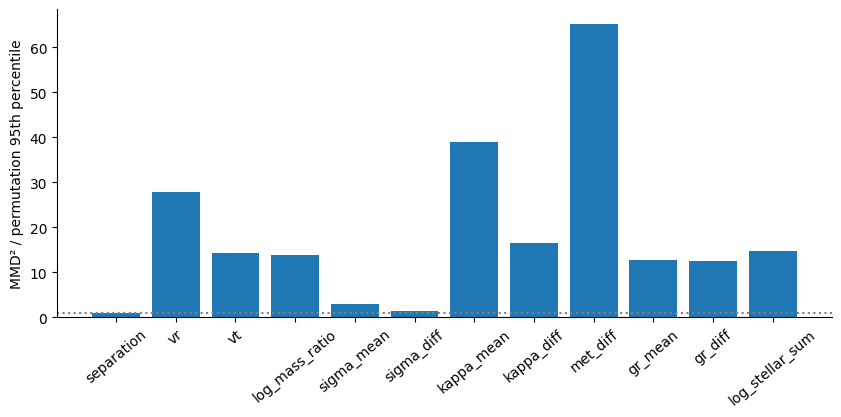

In [2]:
per=table('feature_space/per_feature_mmd.csv')
display(per)
block=table('feature_space/block_mmd_and_heldout_gmm.csv');display(block)
fig,ax=plt.subplots(figsize=(10,4));ax.bar(per.feature,per.ratio_to_null95)
ax.axhline(1,color='gray',ls=':');ax.set_ylabel('MMD² / permutation 95th percentile')
ax.tick_params(axis='x',rotation=40);plt.show()

### Which feature drives the failure?

The ablation compares variants at 500 fixed TNG conditioning rows. For equal-sized
draws in one dimension, W2 is the root mean squared difference of sorted samples;
the experiment averages it over those conditioning rows. Each variant has a separate
200-refit within-FLAMINGO reference. Its interval is the reference distribution, not
a confidence interval on a physical causal effect.


,variant,mean_w2,reference_median,reference_lower,reference_upper,exceedance_fraction,repeats
0,core_morphology,0.188708,0.050984,0.043970,0.063450,0.004975,200
1,morphology_no_sigma,0.116168,0.065629,0.053955,0.089760,0.004975,200
2,morphology_no_kappa,0.193455,0.041895,0.035818,0.052834,0.004975,200
3,morphology_same_host_covar,0.249454,0.051426,0.042963,0.060784,0.004975,200
4,core_chemistry,0.153487,0.049080,0.041808,0.069442,0.004975,200
5,core_photometry,0.127172,0.058406,0.049337,0.077295,0.004975,200


,variant,repeats,reference_median,plus_one_p
0,core_morphology,200,0.050984,0.004975
1,morphology_no_sigma,200,0.065629,0.004975
2,morphology_no_kappa,200,0.041895,0.004975
3,morphology_same_host_covar,200,0.051426,0.004975
4,core_chemistry,200,0.049080,0.004975
5,core_photometry,200,0.058406,0.004975


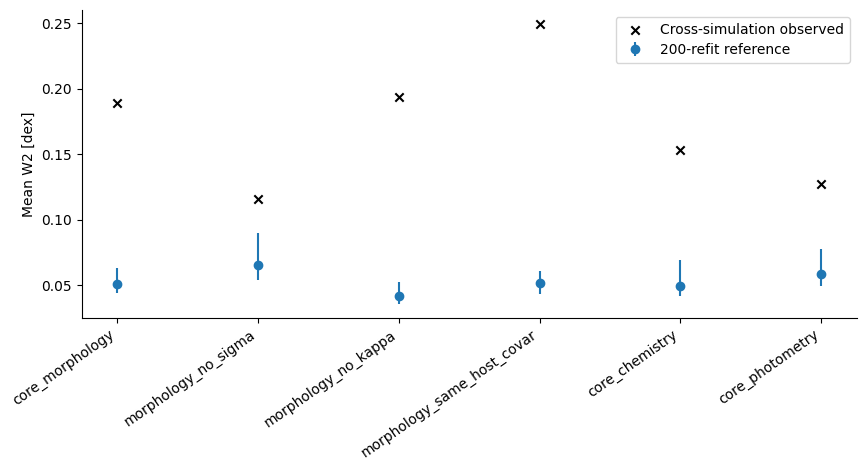

,key,median_beta,rank_cdf_distance,coverage68,coverage95,bias,n_test
0,core_dynamics__full,0.722624,0.262433,0.643791,0.879085,-0.108259,1530
1,core_morphology__full,2.058929,0.687709,0.147712,0.445752,-0.193805,1530
2,morphology_no_sigma__full,0.686397,0.222525,0.658170,0.902614,-0.091533,1530


In [3]:
ablation=table('ablation/ablation_posterior_discrepancy.csv');display(ablation)
repeats=table('bootstrap/ablation_repeats.csv')
check=[]
for row in ablation.itertuples():
    a=repeats.loc[repeats.variant==row.variant,'w2_vs_flam'].to_numpy()
    p=(1+np.count_nonzero(a>=row.mean_w2))/(len(a)+1)
    check.append(dict(variant=row.variant,repeats=len(a),reference_median=np.median(a),plus_one_p=p))
display(pd.DataFrame(check))
fig,ax=plt.subplots(figsize=(10,4));x=np.arange(len(ablation))
ax.errorbar(x,ablation.reference_median,yerr=np.vstack([
    ablation.reference_median-ablation.reference_lower,ablation.reference_upper-ablation.reference_median]),
    fmt='o',label='200-refit reference')
ax.scatter(x,ablation.mean_w2,marker='x',color='black',label='Cross-simulation observed')
ax.set_xticks(x,ablation.variant,rotation=35,ha='right');ax.set_ylabel('Mean W2 [dex]');ax.legend();plt.show()
display(table('ablation/supporting_calibration_all1530.csv'))

Removing dispersion reduces the discrepancy more than removing κcorot. The marginal
dispersion distributions can look similar while the joint relation to mass differs.
The ablation experiments identify an influential input, but it does not show that
feedback is a source of transfer failure. Supporting calibration here uses all 1530
TNG rows and should not be relabelled as the final 231-row held-out comparison.

The [GMM/MMD](../research/notebooks/original/GMM&MMD.ipynb) and
[ablation code](../research/notebooks/original/ablation.ipynb) contain the refit workflow.


[Previous](06_bootstrap_and_sample_size.ipynb) · [Next](08_alternative_mass_targets.ipynb) · [Repository map](../README.md)
